In [1]:
import sys
print(sys.executable)
print(sys.prefix)

c:\Python3.14\python.exe
c:\Python3.14


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

from bin.reconstruct_sim_tree import (
    read_sim_log, build_dendropy_tree, to_biopython_tree, plot_sim_tree,
)

SIM_DIR = Path.cwd()
log_file = SIM_DIR / "data" / "log_eden_subsampled.tsv"
# log_file = SIM_DIR / "data" / "log_eden.tsv"


# "time": death_date - birth_date; "mutation": one unit per generation.
BRANCH_LENGTH = "time"

In [3]:
df = read_sim_log(log_file)
tree = build_dendropy_tree(df, branch_length=BRANCH_LENGTH)

print(tree.as_string(
    schema="newick",
    suppress_leaf_node_labels=False,
    suppress_annotations=False,
))

[&R] ((((((((((((((((((((((((1470:13[&type=center]):1[&type=edge]):1[&type=edge],(((4156:1[&type=center]):1[&type=center]):11[&type=center]):2[&type=edge]):3[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):2[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):2[&type=edge]):1[&type=edge],(((((((((((((((4126:1[&type=center]):5[&type=center]):3[&type=center]):5[&type=center]):7[&type=center]):3[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):2[&type=edge]):1[&type=edge]):2[&type=edge]):1[&type=edge]):1[&type=edge],(((((((((((((((((((((3509:3[&type=center]):4[&type=center]):1[&type=edge]):2[&type=edge]):1[&type=edge]):2[&type=center]):1[&type=edge]):1[&type=edge]):1[&type=edge]):2[&type=edge],(((((3288:4[&type=center]):5[&type=center]):3[&type=center]):1[&type=edge]):2[&type=center]):3[&type=center]):1[&type=edge]):1[&type=edge]):1[&type=edge]):1[&type=edge]):

In [4]:
import pandas as pd

rates_df = pd.read_csv("data/survivor_lineage_mean_birthrate.tsv", sep="\t", dtype={"id": "string"})
birth_rates = dict(zip(rates_df["id"], rates_df["lineage_mean_birthrate"]))

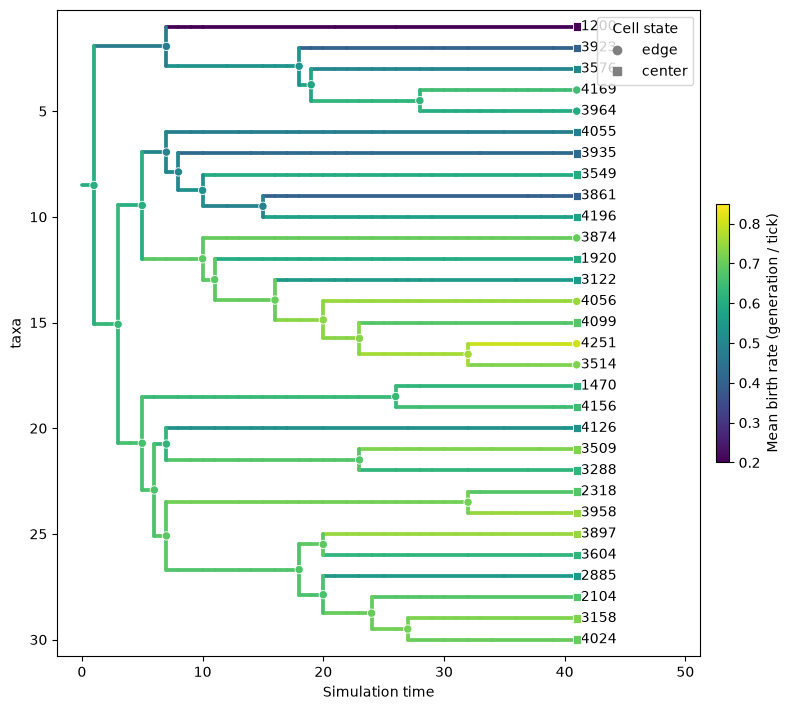

In [5]:

# plot_tree = to_biopython_tree(tree)
# fig, ax = plot_sim_tree(plot_tree)
# ax.set_xlabel("Simulation time" if BRANCH_LENGTH == "time" else "Generation")
# n_tips = plot_tree.count_terminals()
# plt.show()


# Run lineage_mean_birthrate.py first.
plot_tree = to_biopython_tree(tree)

fig, ax = plot_sim_tree(
    plot_tree,
    birth_rates=birth_rates,
    vmin=rates_df["lineage_mean_birthrate"].min(),
    vmax=rates_df["lineage_mean_birthrate"].max(),
)
ax.set_xlabel("Simulation time" if BRANCH_LENGTH == "time" else "Generation")
n_tips = plot_tree.count_terminals()
plt.show()

In [6]:
n_tips

30

In [7]:
import importlib
from bin import compare_trees


importlib.reload(compare_trees)

compare_trees.compare_to_sdevo(tree)

sim: 30 tips, 29 branching ancestors
SDevo: 30 tips, 29 branching ancestors
Tips compared: 30
RF distance: 2  (normalized: 0.036)
Clades only in SDevo: 1
  size 18: ['1200', '1470', '2104', '2318', '2885', '3158', '3288', '3509', '3576', '3604', '3897', '3923', '3958', '3964', '4024', '4126', '4156', '4169']
Clades in sim missed by SDevo: 1
  size 25: ['1470', '1920', '2104', '2318', '2885', '3122', '3158', '3288', '3509', '3514', '3549', '3604', '3861', '3874', '3897', '3935', '3958', '4024', '4055', '4056', '4099', '4126', '4156', '4196', '4251']
Clades only in SDevo: 1
Clades in sim missed by SDevo: 1
Pairwise-depth Spearman rho: 0.693 (p = 2e-63)
Pairwise-depth mean abs error (scaled): 0.051
